# OCS Model Calibration

This part of the pipeline is intended to independently calibrate the OCS classification model in terms of thresholds and anchors.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

from common.configuration import species_invasive


In [2]:
trainval_cls_pred_path = "Save/trainval_classification_predictions.csv"
test_cls_pred_path = "Save/test_classification_predictions.csv"
hist_cls_pred_path = "Save/historical_classification_predictions.csv"

In [3]:
embeddings_colls = [str(i) for i in range(19)]

## Anchors callibration

To callibrate anchors we estimate centers of mass of distributions in training-validation dataset.

In [4]:
trainval_cls_pred_pd = pd.read_csv(trainval_cls_pred_path, index_col=0)
trainval_cls_pred_pd

,full_path,file_name,microscopy_name,label,pred_class,0,1,2,3,4,...,9,10,11,12,13,14,15,16,17,18
0,Dataset\pollen_dataset_kfu_2025\reference_ds\A...,artemisia (106)_0.png,artemisia (106),Artemisia,Artemisia,0.946077,1.375112,0.722548,6.729668,-0.350417,...,-0.506899,-0.231497,-0.975050,-0.430852,0.492580,-0.241263,-0.277289,0.726911,-0.182024,0.172282
1,Dataset\pollen_dataset_kfu_2025\reference_ds\S...,23-04-25 (87)_4.png,23-04-25 (87),Salix,Salix,1.004877,0.509833,-0.198454,0.677748,1.694498,...,0.695033,0.431719,2.122632,-0.533523,0.146861,3.238857,-0.323629,0.265304,-0.139357,-0.017955
2,Dataset\pollen_dataset_kfu_2025\reference_ds\C...,chenopodium (92)_16.png,chenopodium (92),Chenopodiaceae,Chenopodiaceae,-0.146738,0.021623,-0.036037,-0.093720,-0.363894,...,0.086073,-0.098078,-0.118805,0.107981,-0.121311,-0.029517,-0.076879,-0.186557,0.013611,-0.040168
3,Dataset\pollen_dataset_kfu_2025\reference_ds\T...,Tilia_40X (79)_1.png,Tilia_40X (79),Tilia,Tilia,-0.330475,-0.589134,-0.119238,-0.058072,-0.396378,...,-0.225121,-0.534915,-0.026776,-0.098045,0.259386,-0.395177,10.491318,-0.013021,-0.209592,0.319944
4,Dataset\pollen_dataset_kfu_2025\reference_ds\C...,chenopodium (106)_2.png,chenopodium (106),Chenopodiaceae,Chenopodiaceae,-0.341562,-0.051186,-0.042743,-0.128590,-0.081373,...,-0.001690,-0.028353,0.007172,0.116895,-0.034154,0.040479,-0.018464,-0.070659,0.087381,0.053064
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7651,Dataset\pollen_dataset_kfu_2025\reference_ds\Q...,Quercus_40X (12)_2.png,Quercus_40X (12),Quercus,Quercus,0.924966,0.417960,0.356689,-0.158984,-0.764838,...,0.301796,-0.429224,0.049757,7.244943,0.091781,-0.443166,-0.460513,-0.382916,1.227888,0.024857
7652,Dataset\pollen_dataset_kfu_2025\reference_ds\A...,Acer_40X (64)_0.png,Acer_40X (64),Acer,Acer,12.092179,0.193467,-0.647962,0.377755,-0.278108,...,0.315591,-0.207858,0.175338,0.085482,0.200050,-0.596165,0.467991,-0.005381,-1.175288,-0.258542
7653,Dataset\pollen_dataset_kfu_2025\reference_ds\P...,salix (1)_1.png,salix (1),Plantago,Plantago,-0.618044,0.095463,-0.137355,-0.014133,-0.369399,...,12.151058,-0.777895,0.352011,-0.077005,-0.311875,0.853567,0.172607,-0.052041,-0.737481,-0.270461
7654,Dataset\pollen_dataset_kfu_2025\reference_ds\P...,Poaceae (41)_0.png,Poaceae (41),Poaceae,Poaceae,-0.028216,0.261078,-0.089568,0.234451,-0.076054,...,1.236169,8.806637,0.301351,0.087123,0.388161,-0.021568,-0.054511,-0.143656,0.005723,0.190263


In [5]:
from scipy.stats import skew

def evaluate_anchor(df, label):
    df = df[df.label == label]
    positions: np.ndarray = df[embeddings_colls].to_numpy()
    anchor = np.median(positions, axis=0)
    std = np.std(positions, axis=0)
    return anchor, std

In [65]:
anchors = {}
anchor_to_label = {}
label_to_index = {}
anchors_np = np.zeros((19, 19))
thresholds_np = np.zeros((19, 19))
for l in trainval_cls_pred_pd.label.unique():
    a, s = evaluate_anchor(trainval_cls_pred_pd, l)
    anchors[l] = a
    anchors_np[np.argmax(a)] = a
    anchor_to_label[np.argmax(a)] = l
    label_to_index[l] = np.argmax(a)
    thresholds_np[np.argmax(a)] = 5 * s # 2 sigma to cover ~95% of distribution

In [ ]:
# # 1. Create a DataFrame from the 2D array
# df = pd.DataFrame(anchors_np)

# # 2. Name the index and columns after their axis numbers
# df.index.name = 0
# df.columns.name = 1

# # 3. Convert to long format (each cell becomes a row)
# anchors_df = df.stack().reset_index(name='anchor_value')

# # 4. Save to CSV
# anchors_df.to_csv('anchors.csv', index=False)

array([[ 8.57904150e+00,  3.89252750e-02, -2.55154640e-01,
         9.59962600e-04,  1.28036200e-01,  3.70804370e-02,
         5.36145420e-02, -3.83413730e-02, -9.97045800e-02,
        -1.04883280e-01, -2.77450080e-02,  5.43593400e-02,
        -1.08316580e-01,  2.34314200e-02,  1.56139150e-01,
        -8.13520000e-03, -6.14373400e-03, -1.84418660e-01,
         1.32657080e-01],
       [-1.33076580e-01,  8.71189300e+00, -1.64379950e-01,
        -1.90581980e-01,  9.45406400e-02,  4.74858300e-02,
         3.52940100e-01,  7.45825470e-03, -8.16525800e-02,
         5.35660400e-02, -1.89545450e-02,  5.87982830e-02,
        -1.07545674e-01, -2.77900290e-02,  7.58954000e-02,
        -8.79180650e-02, -1.27439800e-01, -1.67070240e-01,
         8.35651760e-02],
       [-2.32202290e-01, -1.03217840e-01,  9.94942500e+00,
         7.04330060e-02, -2.50639620e-02,  8.69487200e-02,
         4.75401880e-02, -5.71930400e-02, -2.98583060e-02,
        -1.49776100e-01,  5.17866000e-03, -5.58286900e-04,
    

## OSC Classification procedure

In [7]:
def classify(item: np.ndarray):    
    distances = np.linalg.norm(anchors_np - item, axis=1)
    closest_class_id = np.argmin(distances)
    closest_label = anchor_to_label[np.argmin(distances)]
    closest_distance = distances[closest_class_id]
    return distances, closest_class_id, closest_label, closest_distance

In [8]:
classify(trainval_cls_pred_pd[embeddings_colls].to_numpy()[250])

(array([13.10350269, 13.41057728, 14.06361396, 13.54266768, 14.04108132,
        14.32870313, 13.97600867, 13.54844343,  1.50274276, 13.64381673,
        12.8904575 , 13.63747002, 13.00979879, 13.44942399, 13.47600305,
        13.72551355, 13.99751753, 13.14712859, 14.64717693]),
 8,
 'Pinus',
 1.502742761775075)

In [9]:
def classify_with_threshold(item: np.ndarray, threshold=4):
    vec_dist = anchors_np - item
    distances = np.linalg.norm(vec_dist, axis=1)
    closest_class_id = np.argmin(distances)
    vec_to_closest_anchor = vec_dist[closest_class_id]
    
    distance_to_anchor = np.linalg.norm(vec_to_closest_anchor)
    is_known = distance_to_anchor < threshold

    _label = anchor_to_label[np.argmin(distances)] if is_known else "Unknown"
    _class_id = closest_class_id if is_known else None
    return distances, _class_id, _label, distance_to_anchor


In [10]:
classify_with_threshold(trainval_cls_pred_pd[embeddings_colls].to_numpy()[250])

(array([13.10350269, 13.41057728, 14.06361396, 13.54266768, 14.04108132,
        14.32870313, 13.97600867, 13.54844343,  1.50274276, 13.64381673,
        12.8904575 , 13.63747002, 13.00979879, 13.44942399, 13.47600305,
        13.72551355, 13.99751753, 13.14712859, 14.64717693]),
 8,
 'Pinus',
 1.502742761775075)

## Tune threshold

In [57]:
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

def optimize_threshold_balanced(X, y, thresholds_range, 
                                      unknown_label="Unknown", 
                                      alpha=0.5,
                                      min_samples_per_class=1):
    """
    Optimizes threshold using classify_with_threshold with CLASS-BALANCED metrics.
    
    Key difference: Sensitivity is MACRO-AVERAGED across known classes
    (each known class contributes equally, regardless of sample count).
    
    Parameters:
    -----------
    X : array-like of shape (n_samples, n_features)
    y : array-like of true labels
    thresholds_range : 1D array of candidate thresholds to test
    unknown_label : string marker for unknown samples
    alpha : weight for balanced sensitivity (1-alpha for specificity)
    min_samples_per_class : skip classes with fewer samples in metric calculation
    
    Returns:
    --------
    best_thresh : optimal threshold value
    results : list of dicts with per-threshold metrics
    """
    y_arr = np.asarray(y)
    
    # Identify known classes (exclude unknown_label)
    known_classes = sorted([c for c in np.unique(y_arr) if c != unknown_label])
    if len(known_classes) == 0:
        raise ValueError("No known classes found in validation labels.")
    
    true_unknown = (y_arr == unknown_label)
    n_unknown = true_unknown.sum()
    if n_unknown == 0:
        print(" Warning: No unknown samples in validation set. Specificity will be NaN.")
    
    results = []
    best_thresh = None
    best_score = -np.inf
    
    for t in thresholds_range:
        # Uses your exact function - no modifications
        preds = np.array([classify_with_threshold(item, threshold=t)[2] for item in X])
        
        # --- SPECIFICITY: Unknown rejection rate ---
        if n_unknown > 0:
            correct_rejected = np.sum(true_unknown & (preds == unknown_label))
            specificity = correct_rejected / n_unknown
        else:
            specificity = np.nan  # Cannot compute without unknowns
        
        # --- SENSITIVITY: MACRO-AVERAGED across known classes ---
        class_recalls = []
        for cls in known_classes:
            mask_true = (y_arr == cls)
            n_cls = mask_true.sum()
            
            if n_cls < min_samples_per_class:
                continue  # Skip underrepresented classes
                
            # Correct predictions for this class: predicted as this class AND not unknown
            correct = np.sum(mask_true & (preds == cls))
            recall = correct / n_cls
            class_recalls.append(recall)
        
        if len(class_recalls) == 0:
            macro_sensitivity = 0.0
        else:
            macro_sensitivity = np.mean(class_recalls)
        
        # --- COMBINED SCORE ---
        if np.isnan(specificity):
            # Fallback: optimize only macro-sensitivity if no unknowns
            score = macro_sensitivity
        else:
            score = alpha * macro_sensitivity + (1 - alpha) * specificity
        
        results.append({
            "threshold": t,
            "macro_sensitivity": macro_sensitivity,
            "specificity": specificity,
            "score": score,
            "class_recalls": dict(zip(known_classes, class_recalls))
        })
            
    macro_sensitivitys = np.array([r["macro_sensitivity"] for r in results])
    specificitys = np.array([r["specificity"] for r in results])
    best_thresh = thresholds_range[(np.argmin(np.abs(macro_sensitivitys - specificitys)))]
    return best_thresh, results

## OCS Performance evaluation

### Load and prepare subsets

In [12]:
trainval_ref_x = trainval_cls_pred_pd[embeddings_colls].to_numpy()
trainval_ref_y = trainval_cls_pred_pd["label"]

In [13]:
test_cls_pred_pd = pd.read_csv(test_cls_pred_path, index_col=0)
test_cls_pred_pd = test_cls_pred_pd.sort_values(by="label", ignore_index=True)
test_cls_pred_masked_pd = test_cls_pred_pd.copy()
for m_label in species_invasive:
    test_cls_pred_masked_pd.loc[test_cls_pred_masked_pd.label == m_label, "label"] = "Unknown"

test_ref_x = test_cls_pred_masked_pd[embeddings_colls].to_numpy()
test_ref_y = test_cls_pred_masked_pd["label"]

test_ref_unmasked_y = test_cls_pred_pd["label"]

Optimal threshold: 4.333
  Macro-sensitivity: 0.908
  Specificity: 0.361


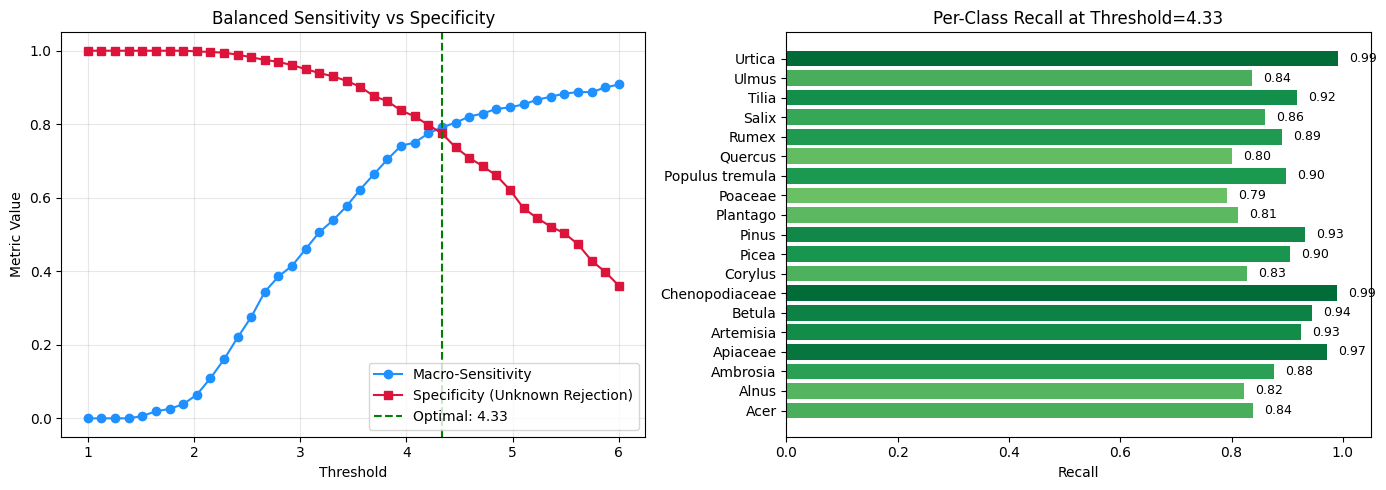

In [14]:
# 1. Define threshold search space
# Tip: start narrow around your current value (4), then expand if needed
thresholds_to_test = np.linspace(1.0, 6.0, 40)

# 2. Optimize
optimal_thresh, metrics = optimize_threshold_balanced(
    X=np.concatenate([trainval_ref_x, test_ref_x]),
    y=np.concatenate([trainval_ref_y, test_ref_y]),
    thresholds_range=thresholds_to_test,
    unknown_label="Unknown",
)
# optimal_thresh, metrics = optimize_threshold_balanced(
#     X=test_ref_x,
#     y=test_ref_y,
#     thresholds_range=thresholds_to_test,
#     unknown_label="Unknown",
# )

print(f"Optimal threshold: {optimal_thresh:.3f}")
print(f"  Macro-sensitivity: {metrics[-1]['macro_sensitivity']:.3f}")
print(f"  Specificity: {metrics[-1]['specificity']:.3f}")

# 3. Plot trade-off + per-class recall heatmap
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Main trade-off curve
sens = [m["macro_sensitivity"] for m in metrics]
spec = [m["specificity"] for m in metrics]
threshs = [m["threshold"] for m in metrics]

ax1.plot(threshs, sens, 'o-', label='Macro-Sensitivity', color='dodgerblue')
ax1.plot(threshs, spec, 's-', label='Specificity (Unknown Rejection)', color='crimson')
ax1.axvline(optimal_thresh, color='green', linestyle='--', label=f'Optimal: {optimal_thresh:.2f}')
ax1.set_xlabel('Threshold')
ax1.set_ylabel('Metric Value')
ax1.set_title('Balanced Sensitivity vs Specificity')
ax1.grid(True, alpha=0.3)
ax1.legend()

# Per-class recall at optimal threshold (heatmap)
opt_metrics = next(m for m in metrics if abs(m["threshold"] - optimal_thresh) < 1e-5)
class_recalls = opt_metrics["class_recalls"]
if class_recalls:
    classes = list(class_recalls.keys())
    recalls = [class_recalls[c] for c in classes]
    colors = plt.cm.RdYlGn(recalls)
    bars = ax2.barh(classes, recalls, color=colors)
    ax2.set_xlabel('Recall')
    ax2.set_title(f'Per-Class Recall at Threshold={optimal_thresh:.2f}')
    ax2.set_xlim(0, 1.05)
    for i, (bar, val) in enumerate(zip(bars, recalls)):
        ax2.text(val + 0.02, i, f'{val:.2f}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

### Prediction with oprimal threshold

In [15]:
trainval_ref_pred  = [classify_with_threshold(item, optimal_thresh)[2] for item in trainval_ref_x]
test_ref_pred = [classify_with_threshold(item, optimal_thresh)[2] for item in test_ref_x]

### Plot confusion matrixes

In [16]:
def plot_confusion_matrix(y_true, y_pred):
    classes = sorted(set(y_true) | set(y_pred))
    if "Unknown" in classes:
        classes.remove("Unknown")
    classes.append("Unknown")
    cm = confusion_matrix(y_true, y_pred, labels=classes)
    plt.figure(figsize=(16, 12))

    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Blues',
                xticklabels=classes, yticklabels=classes)

    plt.xlabel('Predicted Label', fontsize=12)
    plt.ylabel('True Label', fontsize=12)
    plt.title('Normalized Confusion Matrix', fontsize=14)
    plt.tight_layout()
    plt.show()

#### Train-val subset

C:\Users\siniz\AppData\Local\Temp\ipykernel_8732\1512431160.py:9: RuntimeWarning: invalid value encountered in divide
  cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]


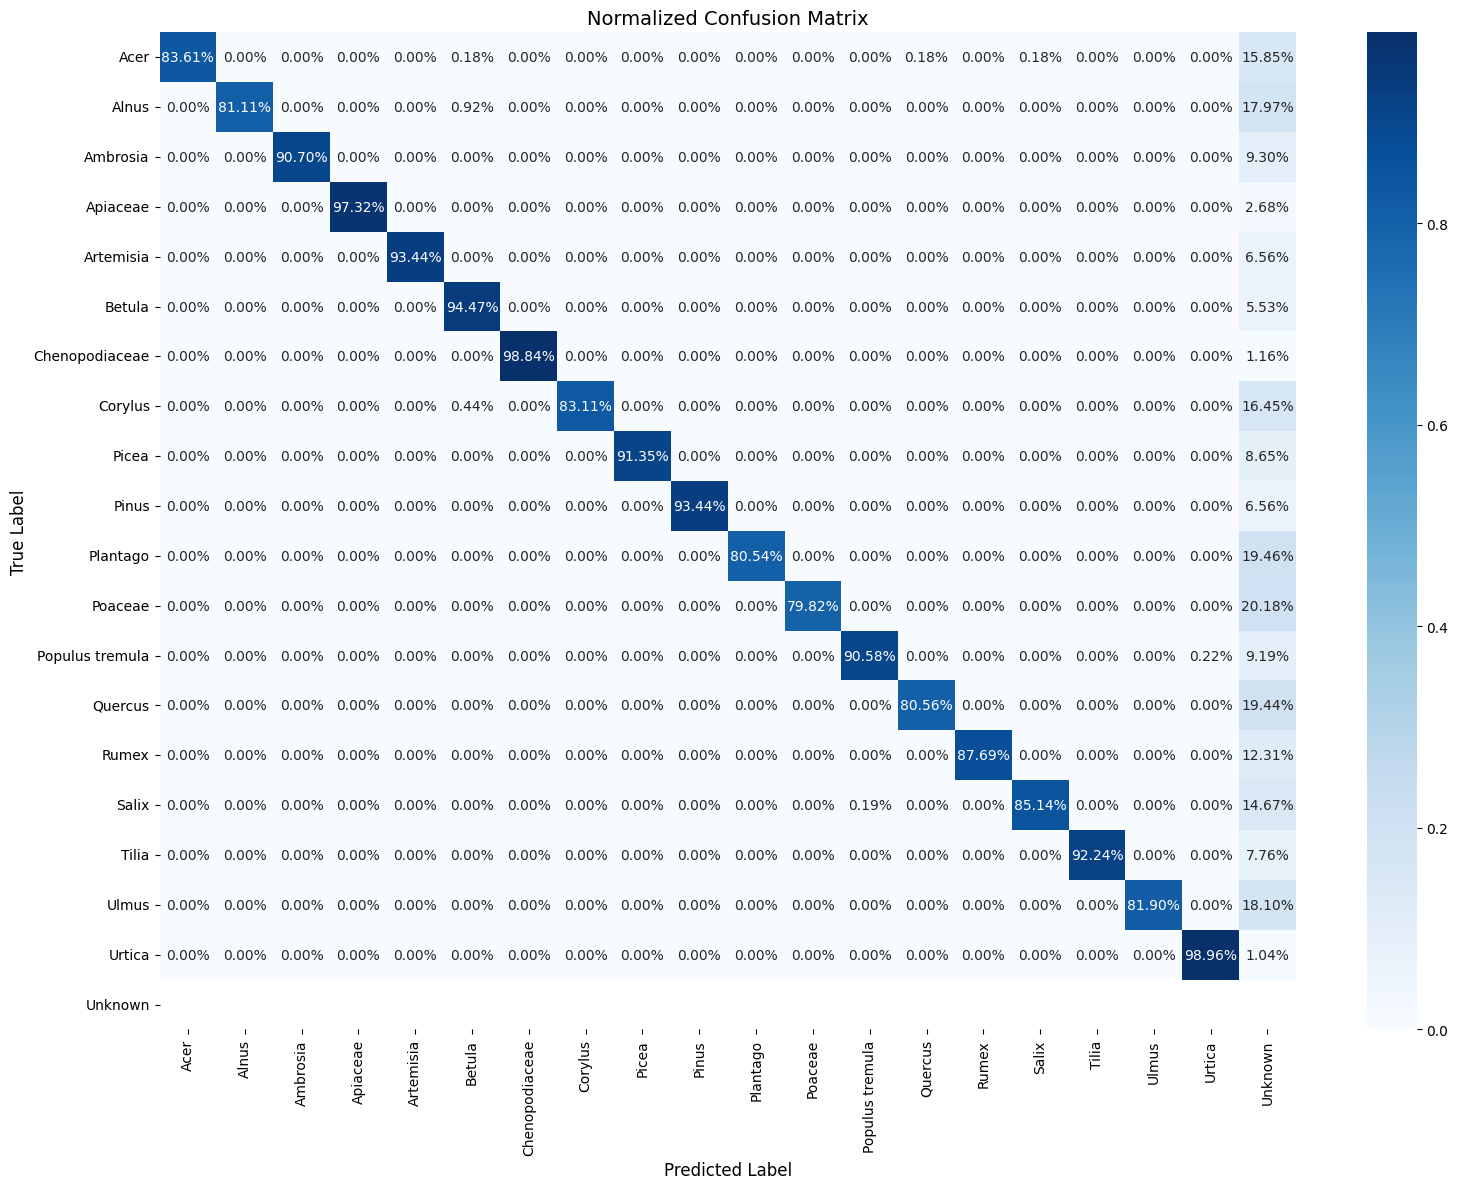

In [17]:
plot_confusion_matrix(trainval_ref_y, trainval_ref_pred)

### Test reference subset

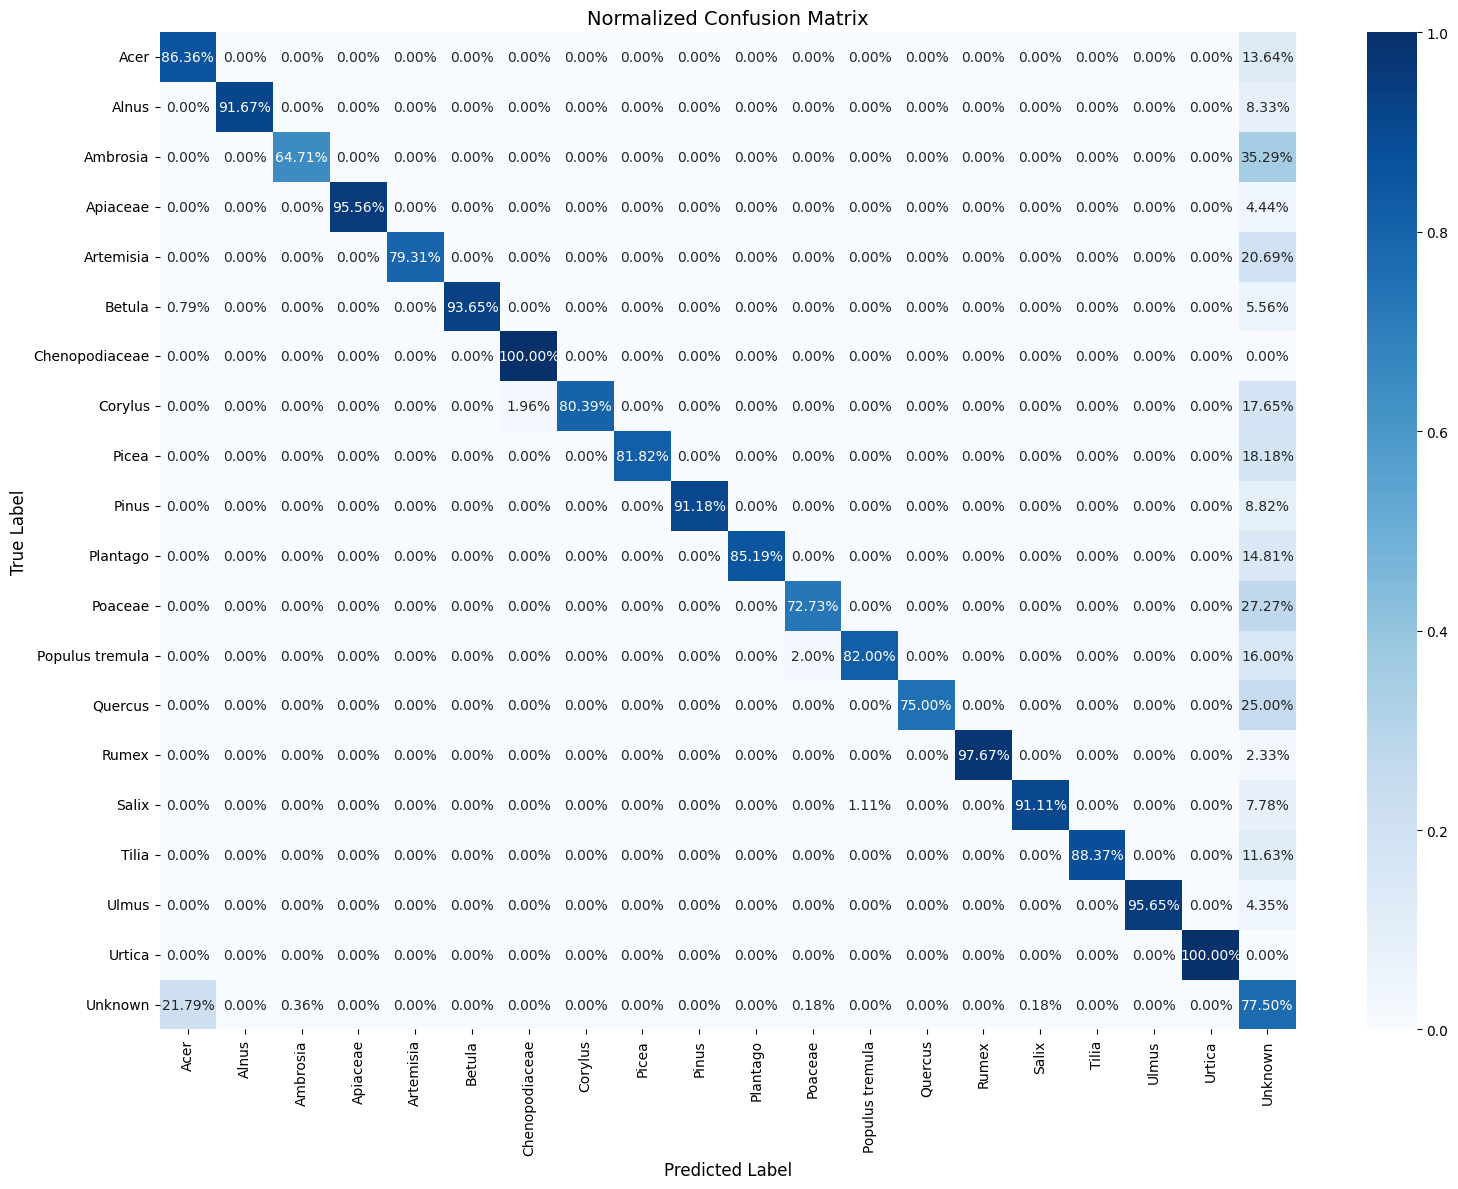

In [18]:
plot_confusion_matrix(test_ref_y, test_ref_pred)

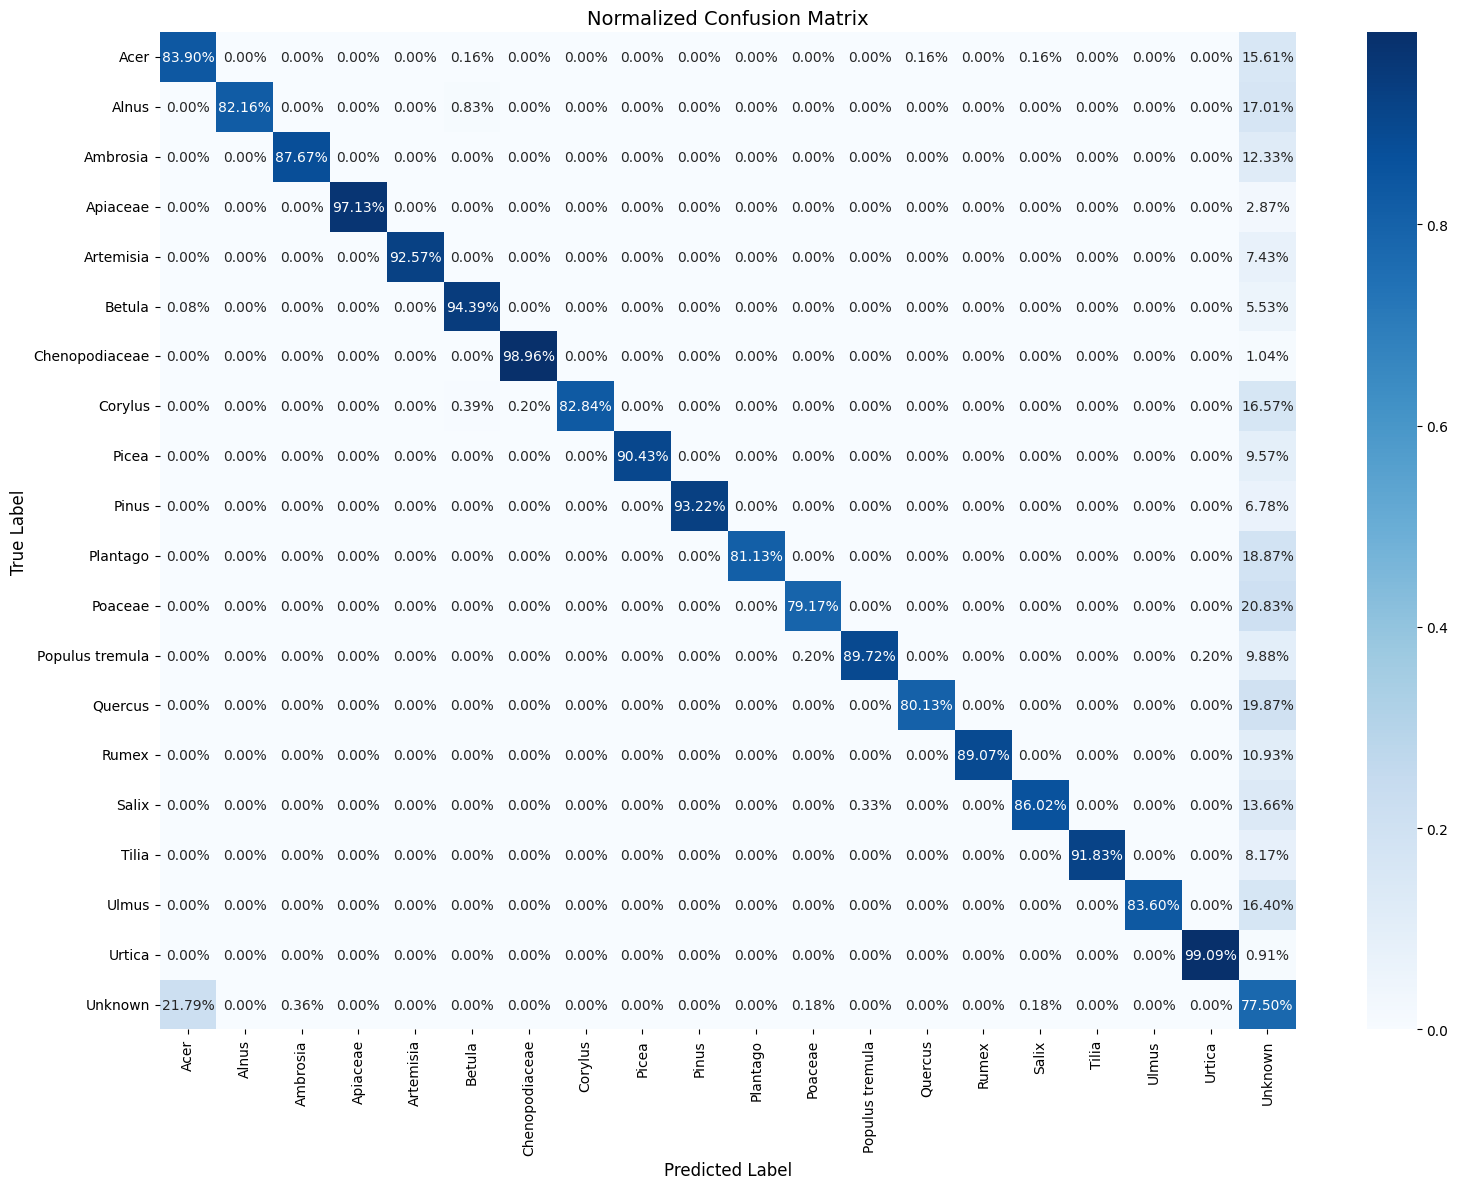

In [19]:
plot_confusion_matrix(
    np.concatenate([trainval_ref_y, test_ref_y]), 
    np.concatenate([trainval_ref_pred, test_ref_pred])
)

## Distance map

In [20]:
def prepare_data(embeddings_lists: list, labels_lists: pd.Series):
    all_labels_sorted = []
    all_embeddings_sorted = []
    class_boundaries = []
    # labels_lists = labels_lists.reindex(index=range(len(labels_lists)))
 
    class_boundaries.append(len(all_labels_sorted))
    for l in labels_lists.unique():
        last_index = labels_lists[labels_lists == l].index[-1]
        class_boundaries.append(last_index)
    class_boundaries.sort()
    return labels_lists, embeddings_lists, class_boundaries

def add_class_markings(ax, class_boundaries, labels):
    tick_locs = [(class_boundaries[i] + class_boundaries[i+1] - 1) / 2 for i in range(len(class_boundaries)-1)]
    ax.set_xticks(tick_locs)
    ax.set_yticks(tick_locs)
    ax.set_xticklabels([labels[int(loc)] for loc in tick_locs])
    ax.set_yticklabels([labels[int(loc)] for loc in tick_locs])
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    for boundary in class_boundaries[1:-1]:
        ax.axhline(y=boundary-1, color='k', linestyle='-', linewidth=1)
        ax.axvline(x=boundary-1, color='k', linestyle='-', linewidth=1)


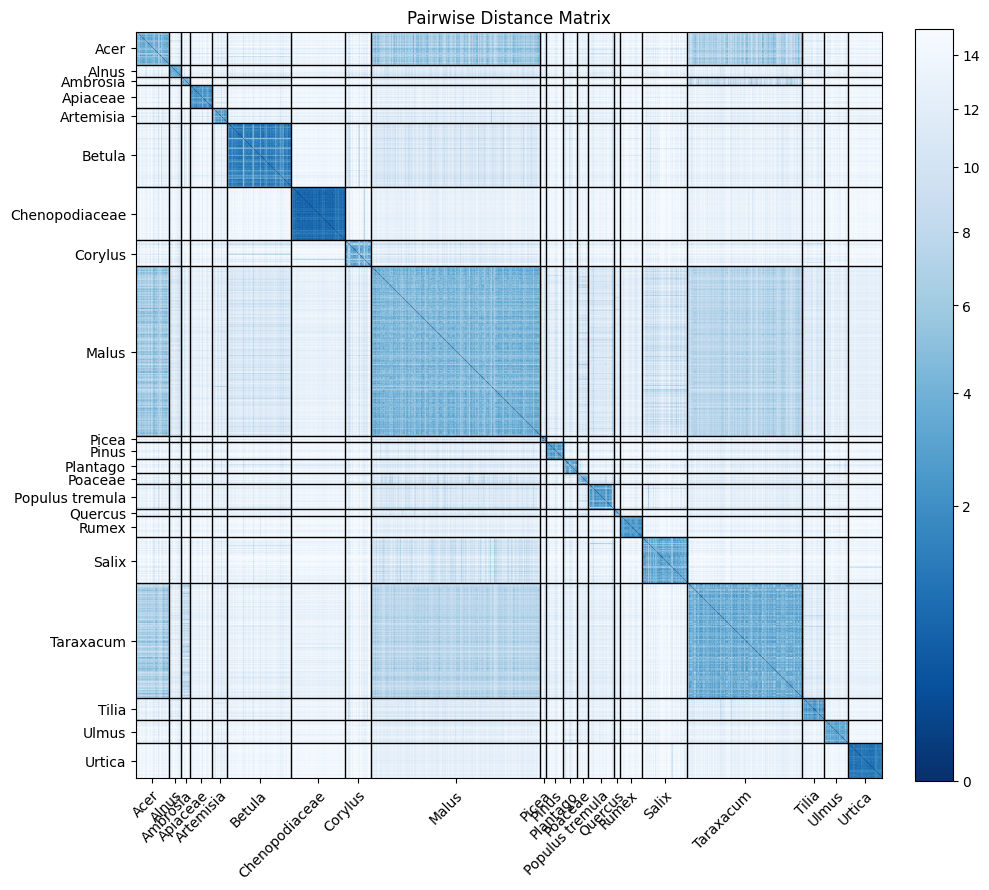

In [21]:
from sklearn.metrics import pairwise_distances
from matplotlib.colors import PowerNorm

all_labels_sorted, all_embeddings_sorted, class_boundaries = prepare_data(test_ref_x, test_ref_unmasked_y)


pairwise_dist = pairwise_distances(test_ref_x, metric="euclidean")#cosine
fig, ax = plt.subplots(figsize=(10, 10))
im = ax.imshow(pairwise_dist, cmap='Blues_r', norm=PowerNorm(gamma=0.5, vmin=0, vmax=15))#
plt.colorbar(im, fraction=0.046, pad=0.04)

add_class_markings(ax, class_boundaries, all_labels_sorted)


plt.title('Pairwise Distance Matrix')
plt.tight_layout()
plt.show()

## Historical data

In [41]:
hist_cls_pred_pd = pd.read_csv(hist_cls_pred_path, index_col=0)
# hist_cls_pred_masked_pd = hist_cls_pred_pd.copy()

hist_cls_pred_pd.loc[hist_cls_pred_pd.label == "0_Unknown-pollen", "label"] = "Unknown"
hist_cls_pred_pd.loc[hist_cls_pred_pd.label == "0_Not pollen", "label"] = "Unknown"
hist_cls_pred_pd.loc[hist_cls_pred_pd.label == "Populus", "label"] = "Populus tremula"


hist_cls_pred_pd = hist_cls_pred_pd.sort_values(by="label", ignore_index=True)

hist_x = hist_cls_pred_pd[embeddings_colls].to_numpy()
hist_y = hist_cls_pred_pd["label"]

In [42]:
hist_cls_pred_pd

,full_path,file_name,microscopy_name,label,pred_class,0,1,2,3,4,...,9,10,11,12,13,14,15,16,17,18
0,Dataset/pollen_dataset_kfu_2025\historical_cla...,1 may (274)_0.png,1 may (274),Acer,Acer,6.670476,2.302062,-0.276415,1.292893,-0.399964,...,-0.457325,0.124322,0.218489,-0.337553,0.020106,-1.227565,0.166015,-0.589689,1.270612,0.851831
1,Dataset/pollen_dataset_kfu_2025\historical_cla...,1 may (272)_14.png,1 may (272),Acer,Acer,8.708616,0.707254,0.263459,-0.760741,-0.214144,...,-0.008472,-0.067928,0.634572,-0.468294,-0.186638,-0.341028,0.065472,-0.011047,-0.404884,0.718583
2,Dataset/pollen_dataset_kfu_2025\historical_cla...,1 may (272)_11.png,1 may (272),Acer,Acer,5.551549,0.930290,-0.505325,0.800852,1.492203,...,0.053235,0.211554,1.042672,-0.575638,-0.265639,1.227719,0.012736,0.075383,0.439532,1.950797
3,Dataset/pollen_dataset_kfu_2025\historical_cla...,1 may (272)_10.png,1 may (272),Acer,Acer,6.146332,0.608705,1.145941,0.357353,0.412563,...,-0.170384,-0.146986,0.256097,-0.478393,-0.186789,0.547542,-0.417419,-0.306131,0.417431,0.268670
4,Dataset/pollen_dataset_kfu_2025\historical_cla...,1 may (272)_0.png,1 may (272),Acer,Acer,4.789916,0.679445,0.100498,1.569635,2.060895,...,-0.162362,-0.035921,0.318693,-0.399937,-0.451065,-0.391417,0.456882,-0.187343,-0.251736,0.461552
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5725,Dataset/pollen_dataset_kfu_2025\historical_cla...,ff (100)_16.png,ff (100),Urtica,Urtica,-0.125614,-0.214980,0.004910,-0.212468,0.246909,...,0.056242,-0.139749,-0.510272,-0.048452,0.135863,0.087838,-0.064322,10.614077,-0.064376,-0.063472
5726,Dataset/pollen_dataset_kfu_2025\historical_cla...,ff (100)_17.png,ff (100),Urtica,Urtica,0.023445,-0.025927,0.125603,0.071861,0.263320,...,0.700361,-0.250842,-0.674679,-0.179868,0.273824,0.137930,-0.039535,9.734027,-0.395770,-0.082431
5727,Dataset/pollen_dataset_kfu_2025\historical_cla...,ff (100)_18.png,ff (100),Urtica,Urtica,-0.225803,-0.343015,-0.236599,0.332359,0.374136,...,0.284612,-0.161289,0.399631,-0.050750,0.030876,0.193982,-0.068076,8.771788,-0.064019,0.022231
5728,Dataset/pollen_dataset_kfu_2025\historical_cla...,ff (1)_2.png,ff (1),Urtica,Urtica,-0.207380,-0.794330,-0.003555,-0.279691,0.070358,...,0.323811,-0.053599,-0.399007,-0.024341,0.816072,0.672533,-0.019032,9.702824,-0.190177,-0.012790


In [76]:
hist_pred  = [classify_with_threshold(item, 5.38)[2] for item in hist_x]

C:\Users\siniz\AppData\Local\Temp\ipykernel_8732\1512431160.py:9: RuntimeWarning: invalid value encountered in divide
  cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]


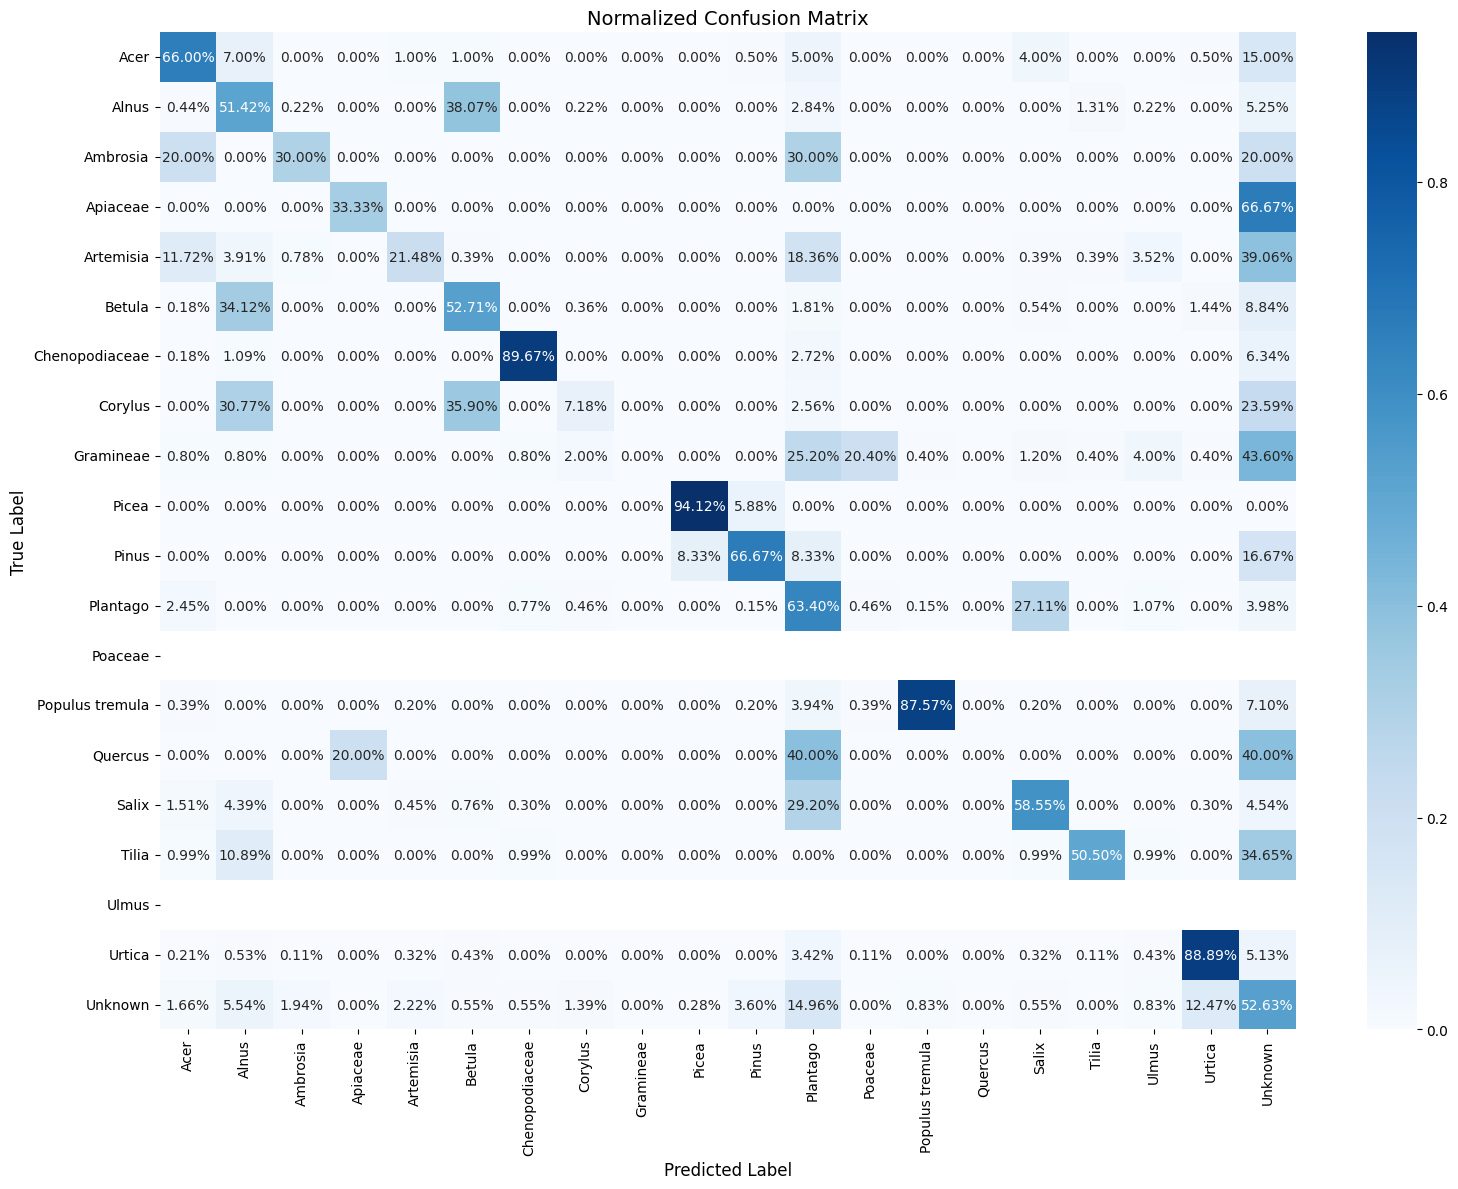

In [77]:
plot_confusion_matrix(hist_y, hist_pred)

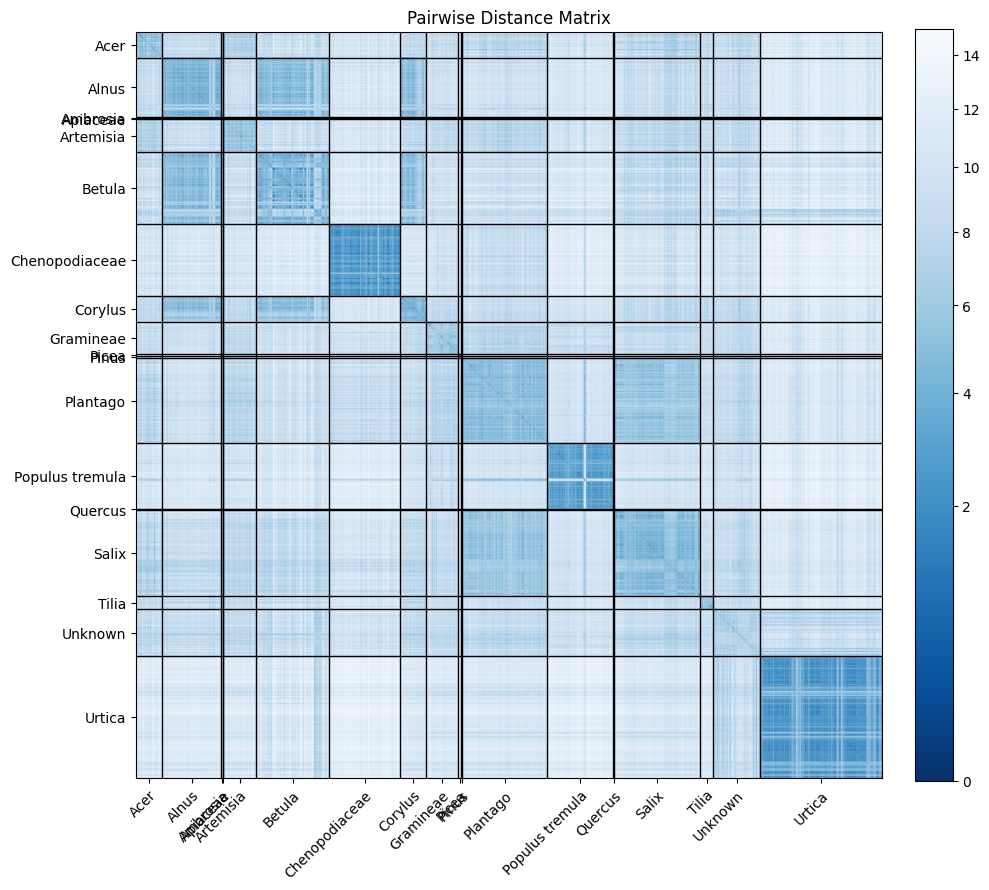

In [78]:
all_labels_sorted, all_embeddings_sorted, class_boundaries = prepare_data(hist_x, hist_y)


pairwise_dist = pairwise_distances(hist_x, metric="euclidean")#cosine
fig, ax = plt.subplots(figsize=(10, 10))
im = ax.imshow(pairwise_dist, cmap='Blues_r', norm=PowerNorm(gamma=0.5, vmin=0, vmax=15))#
plt.colorbar(im, fraction=0.046, pad=0.04)

add_class_markings(ax, class_boundaries, all_labels_sorted)


plt.title('Pairwise Distance Matrix')
plt.tight_layout()
plt.show()

Optimal threshold: 5.385
  Macro-sensitivity: 0.567
  Specificity: 0.000


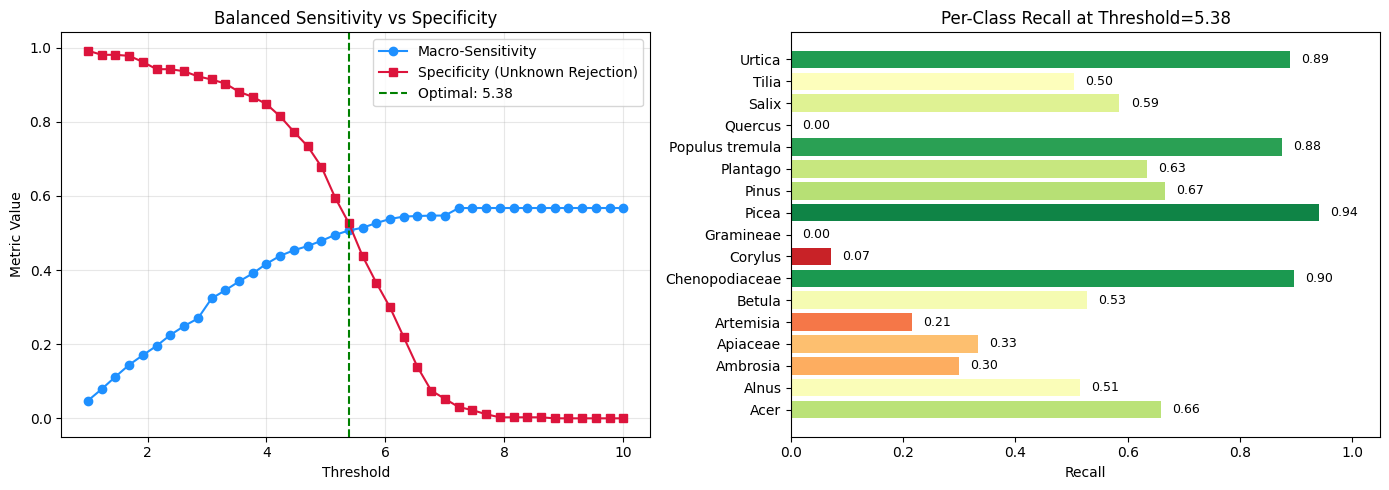

In [75]:
# 1. Define threshold search space
# Tip: start narrow around your current value (4), then expand if needed
thresholds_to_test = np.linspace(1.0, 10.0, 40)

# 2. Optimize

optimal_thresh, metrics = optimize_threshold_balanced(
    X=hist_x,
    y=hist_y,
    thresholds_range=thresholds_to_test,
    unknown_label="Unknown",
)

print(f"Optimal threshold: {optimal_thresh:.3f}")
print(f"  Macro-sensitivity: {metrics[-1]['macro_sensitivity']:.3f}")
print(f"  Specificity: {metrics[-1]['specificity']:.3f}")

# 3. Plot trade-off + per-class recall heatmap
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Main trade-off curve
sens = [m["macro_sensitivity"] for m in metrics]
spec = [m["specificity"] for m in metrics]
threshs = [m["threshold"] for m in metrics]

ax1.plot(threshs, sens, 'o-', label='Macro-Sensitivity', color='dodgerblue')
ax1.plot(threshs, spec, 's-', label='Specificity (Unknown Rejection)', color='crimson')
ax1.axvline(optimal_thresh, color='green', linestyle='--', label=f'Optimal: {optimal_thresh:.2f}')
ax1.set_xlabel('Threshold')
ax1.set_ylabel('Metric Value')
ax1.set_title('Balanced Sensitivity vs Specificity')
ax1.grid(True, alpha=0.3)
ax1.legend()

# Per-class recall at optimal threshold (heatmap)
opt_metrics = next(m for m in metrics if abs(m["threshold"] - optimal_thresh) < 1e-5)
class_recalls = opt_metrics["class_recalls"]
if class_recalls:
    classes = list(class_recalls.keys())
    recalls = [class_recalls[c] for c in classes]
    colors = plt.cm.RdYlGn(recalls)
    bars = ax2.barh(classes, recalls, color=colors)
    ax2.set_xlabel('Recall')
    ax2.set_title(f'Per-Class Recall at Threshold={optimal_thresh:.2f}')
    ax2.set_xlim(0, 1.05)
    for i, (bar, val) in enumerate(zip(bars, recalls)):
        ax2.text(val + 0.02, i, f'{val:.2f}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

In [73]:
anchors = {}
anchor_to_label = {}
label_to_index = {}
anchors_np = np.zeros((19, 19))

all_data_pd = pd.concat([hist_cls_pred_pd, trainval_cls_pred_pd, test_cls_pred_masked_pd])
for l in trainval_cls_pred_pd.label.unique():
    _a, _s = evaluate_anchor(trainval_cls_pred_pd, l)
    a, s = evaluate_anchor(all_data_pd, l)
    anchors[l] = a
    anchors_np[np.argmax(_a)] = a
    anchor_to_label[np.argmax(_a)] = l
    label_to_index[l] = np.argmax(a)

In [74]:
anchor_to_label

{3: 'Artemisia',
 14: 'Salix',
 5: 'Chenopodiaceae',
 15: 'Tilia',
 18: 'Ambrosia',
 6: 'Corylus',
 9: 'Plantago',
 16: 'Urtica',
 2: 'Apiaceae',
 4: 'Betula',
 0: 'Acer',
 10: 'Poaceae',
 12: 'Quercus',
 1: 'Alnus',
 17: 'Ulmus',
 11: 'Populus tremula',
 13: 'Rumex',
 8: 'Pinus',
 7: 'Picea'}